# Night-sky background at Observatorio del Roque de los Muchachos with nsb-py

### Equatorial and horizontal targets, component radiance and observation windows

**nsb-py** predicts optical **night-sky photon radiance** in the default **300–650 nm** band
(photons cm⁻² ns⁻¹ sr⁻¹) by combining integrated **starlight**, **airglow**, **zodiacal light**
and scattered **moonlight**. The predictions depend on observer location, UTC time and
viewing direction.

For CTAO and other imaging atmospheric Cherenkov observatories, that radiance sets the
optical background against which Cherenkov flashes must be detected. Planning and
instrument studies therefore need a reproducible sky model that can be evaluated for a
chosen site, instant and pointing — including both celestial (equatorial) targets and
fixed local Alt/Az pointings.

This notebook is an **illustrative capabilities demonstration** at the
**Observatorio del Roque de los Muchachos / CTAO-North** planning coordinates shipped with
NSB. Numbers are model predictions for declared inputs, **not** observational accuracy,
LST-1 camera measurements, site calibration or CTAO endorsement. For comparisons with
published sky spectra, see [observational validation](observational-validation.ipynb).

The examples cover:

1. Component-separated radiance for one declared scenario.
2. Native **equatorial** and **horizontal** targets in the same `PointQuery` API.
3. How radiance changes with time and with local pointing.
4. `ThresholdQuery` observation-window searches in **both** frames.

Code: AGPL-3.0-only, Copyright (C) 2026 Vallés Puig, Ramon. Upstream data retain their source terms.


## 1. Environment and reproducibility

Select a fresh **CPython 3.12 or 3.13** Jupyter kernel and **Run All**.

The next cell installs **`nsb-py==0.3.0` and `siderust==0.6.0` from PyPI**,
together with NumPy, Matplotlib and Astropy, using the current kernel's Python.
Native `siderust.direction.ICRS` and `siderust.direction.Horizontal` targets are
supported by these published releases. No local checkout or Rust toolchain is required.
The distribution is `nsb-py`, imported as `nsb`; do not install the unrelated `nsb` package.

Matching installed versions are reused. If an already imported package changes,
restart the kernel and Run All. Results are generated inline from bundled NSB
assets; no files are exported. Installation requires compatible published wheels.


In [1]:
# Run this cell first, using a CPython 3.12 or 3.13 kernel.
import importlib
import importlib.metadata as metadata
import json
from pathlib import Path
import subprocess
import sys

if sys.implementation.name != "cpython" or sys.version_info[:2] not in ((3, 12), (3, 13)):
    raise RuntimeError("Select a CPython 3.12 or 3.13 kernel, then Run All.")

# nsb-py is the distribution; nsb is its Python import. Do not install 'nsb'.
REQUIREMENTS = ['nsb-py==0.3.0', 'siderust==0.6.0', 'numpy>=2,<3', 'matplotlib>=3.8,<4', 'astropy>=6.1,<9']
try:
    metadata.distribution("nsb")
except metadata.PackageNotFoundError:
    pass
else:
    raise RuntimeError("Remove the unrelated 'nsb' distribution with this kernel's pip, then restart.")

# Remember loaded dependencies so changes cannot silently leave stale imports.
loaded = {name: metadata.version(name)
          for module, names in metadata.packages_distributions().items()
          if module in sys.modules for name in names}
pip = [sys.executable, "-m", "pip", "install", "--index-url", "https://pypi.org/simple"]
try:
    nsb_dist = metadata.distribution("nsb-py")
    direct = json.loads(nsb_dist.read_text("direct_url.json") or "{}")
except metadata.PackageNotFoundError:
    nsb_dist, direct = None, {}
if nsb_dist is not None and (nsb_dist.version != "0.3.0" or direct):
    if "nsb" in sys.modules:
        raise RuntimeError("Restart the kernel before selecting nsb-py==0.3.0 from PyPI.")
    subprocess.run(pip + ["--only-binary=:all:", "--no-deps", "--force-reinstall", "nsb-py==0.3.0"], check=True)
subprocess.run(pip + ["--only-binary=nsb-py", *REQUIREMENTS], check=True)

importlib.invalidate_caches()
changed = [name for name, version in loaded.items() if metadata.version(name) != version]
if changed:
    raise RuntimeError(f"Updated already-imported packages: {changed}. Restart the kernel, then Run All.")

# Check that the module resolves to the nsb-py installation, rather than a local file.
nsb_dist = metadata.distribution("nsb-py")
nsb_spec = importlib.util.find_spec("nsb")
owned = {Path(nsb_dist.locate_file(f)).resolve() for f in nsb_dist.files or []}
if nsb_dist.version != "0.3.0" or nsb_spec is None or not nsb_spec.origin or Path(nsb_spec.origin).resolve() not in owned:
    raise RuntimeError("Expected the nsb-py==0.3.0 module. Remove shadowing nsb.py/directories and restart.")
print("Ready: nsb-py", nsb_dist.version)


Ready: nsb-py 0.3.0


In [2]:
from datetime import datetime, timedelta, timezone
import importlib.metadata as metadata

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Markdown, display
import nsb
import siderust

UNIT = "photons cm⁻² ns⁻¹ sr⁻¹"
print("NSB:", getattr(nsb, "__version__", metadata.version("nsb-py")))


NSB: 0.3.0


## 2. Sky-background components

We use the **CTAO-North / Observatorio del Roque de los Muchachos** WGS84 array
coordinates shipped with NSB's public examples (planning coordinates, not a reconstructed
telescope position). Target: **Crab Nebula** in ICRS. UTC: **2024-01-15 02:00**. Solar
input: **F10.7 = 130 sfu** as an explicit planning scenario.

The evaluator returns band-integrated radiance and a per-component budget. Component
fractions are model decomposition for the declared inputs — not measured camera fractions
and not a statement of observational accuracy.


In [3]:
SITE_NAME = "Observatorio del Roque de los Muchachos / CTAO-North (planning)"
LON_DEG, LAT_DEG, HEIGHT_M = -17.892005, 28.762164, 2240.2
WHEN = datetime(2024, 1, 15, 2, 0, tzinfo=timezone.utc)
F107_SFU = 130.0
TARGET_RA_DEG, TARGET_DEC_DEG = 83.633, 22.014  # Crab, ICRS

observer = siderust.Observer(lon_deg=LON_DEG, lat_deg=LAT_DEG, height_m=HEIGHT_M)
equatorial = siderust.direction.ICRS(ra_deg=TARGET_RA_DEG, dec_deg=TARGET_DEC_DEG)
config = (
    nsb.NsbModelConfig.generic_clear_sky()
    .with_site_profile(nsb.SiteProfile.CTA_NORTH)
    .with_solar_radio_flux_sfu(F107_SFU)
)
evaluator = nsb.NsbEvaluator(config)

query = nsb.PointQuery(observer, WHEN, equatorial)
result = evaluator.evaluate(query)

L = result.integrated_photons_cm2_ns_sr
assert np.isfinite(L) and L >= 0
by_component = {c.name: c.integrated_photons_cm2_ns_sr for c in result.components}
assert all(np.isfinite(x) and x >= 0 for x in by_component.values())

print(SITE_NAME)
print(WHEN.isoformat(), "| Crab (ICRS) | 300–650 nm")
print(f"Predicted integrated radiance: {L:.6f} {UNIT}")
for name, value in by_component.items():
    share = f" ({value / L:.1%} of total)" if L > 0 else ""
    print(f"  {name:<12} {value:.6f}{share}")
print("Airglow selection:", evaluator.config.airglow_selection)


Observatorio del Roque de los Muchachos / CTAO-North (planning)
2024-01-15T02:00:00+00:00 | Crab (ICRS) | 300–650 nm
Predicted integrated radiance: 0.324788 photons cm⁻² ns⁻¹ sr⁻¹
  zodiacal     0.120253 (37.0% of total)
  starlight    0.061096 (18.8% of total)
  airglow      0.143439 (44.2% of total)
  moon         0.000000 (0.0% of total)
Airglow selection: automatic


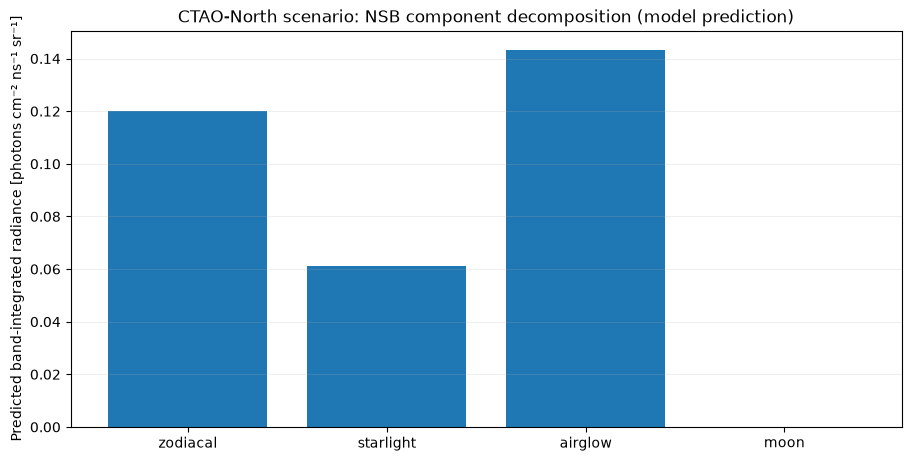

In [4]:
fig, ax = plt.subplots(figsize=(9, 4.5), layout="constrained")
ax.bar(list(by_component), list(by_component.values()))
ax.set(
    ylabel=f"Predicted band-integrated radiance [{UNIT}]",
    title="CTAO-North scenario: NSB component decomposition (model prediction)",
)
ax.grid(axis="y", alpha=0.2)
plt.show()


## 3. Equatorial versus horizontal targets

`PointQuery` accepts both `siderust.direction.ICRS` (ICRS / equatorial) and
`siderust.direction.Horizontal` (geometric Alt/Az) **natively**. Horizontal targets keep
fixed altitude and azimuth at the observer; NSB resolves them to the scientific frame at
each evaluation instant. No pre-conversion to ICRS is required.

Altitude is above the local geometric horizon; azimuth is from North, increasing
clockwise through East. Atmospheric refraction is not applied to query targets.


In [5]:
equatorial = siderust.direction.ICRS(ra_deg=83.633, dec_deg=22.014)
horizontal = siderust.direction.Horizontal(alt_deg=60.0, az_deg=130.0)
instant = WHEN

for target in (equatorial, horizontal):
    query = nsb.PointQuery(observer, instant, target)
    result = evaluator.evaluate(query)
    frame = type(target).__name__
    value = result.integrated_photons_cm2_ns_sr
    assert np.isfinite(value) and value >= 0
    print(f"{frame:<20} total = {value:.6f} {UNIT}")
    for component in result.components:
        print(f"  {component.name:<12} {component.integrated_photons_cm2_ns_sr:.6f}")


ICRS                 total = 0.324788 photons cm⁻² ns⁻¹ sr⁻¹
  zodiacal     0.120253
  starlight    0.061096
  airglow      0.143439
  moon         0.000000
Horizontal           total = 0.268484 photons cm⁻² ns⁻¹ sr⁻¹
  zodiacal     0.120155
  starlight    0.015328
  airglow      0.133000
  moon         0.000000


## 4. Temporal and pointing-dependent variation

Two complementary sweeps illustrate model sensitivity for the same observer and
configuration:

1. **Pointing:** fixed UTC instant, vary geometric altitude at a fixed azimuth using
   native `siderust.direction.Horizontal` (zenith distances stay inside the ≤60° domain relevant
   to Automatic Airglow / experimental Oxygen).
2. **Time:** fixed Crab ICRS direction, sample a short UTC interval.

These are forecast-sensitivity visualizations for declared inputs — not records of an
actual telescope track or measured observing conditions.


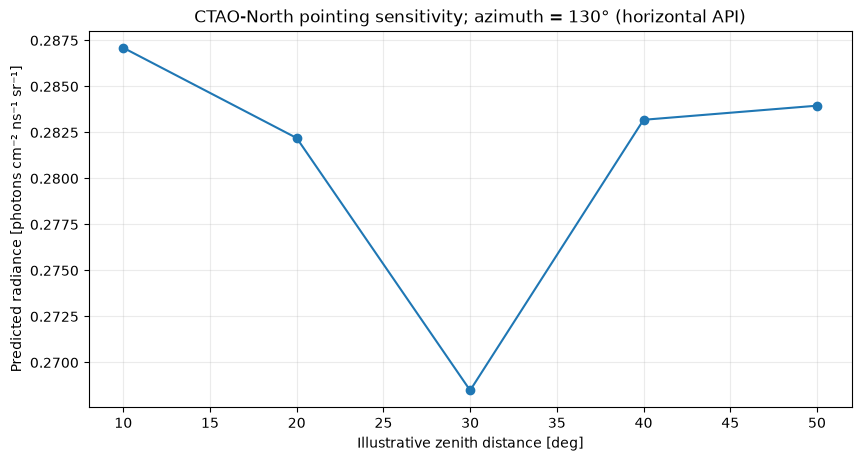

In [6]:
AZ_DEG = 130.0
ZENITH_DISTANCES = [10.0, 20.0, 30.0, 40.0, 50.0]
directional_radiance = []
for zd in ZENITH_DISTANCES:
    pointing = siderust.direction.Horizontal(alt_deg=90.0 - zd, az_deg=AZ_DEG)
    value = evaluator.evaluate(
        nsb.PointQuery(observer, WHEN, pointing)
    ).integrated_photons_cm2_ns_sr
    if not np.isfinite(value) or value < 0:
        raise ValueError(f"Invalid model radiance at zenith distance {zd}")
    directional_radiance.append(value)

fig, ax = plt.subplots(figsize=(8.5, 4.5), layout="constrained")
ax.plot(ZENITH_DISTANCES, directional_radiance, "o-")
ax.set(
    xlabel="Illustrative zenith distance [deg]",
    ylabel=f"Predicted radiance [{UNIT}]",
    title=f"CTAO-North pointing sensitivity; azimuth = {AZ_DEG:.0f}° (horizontal API)",
)
ax.grid(alpha=0.25)
plt.show()


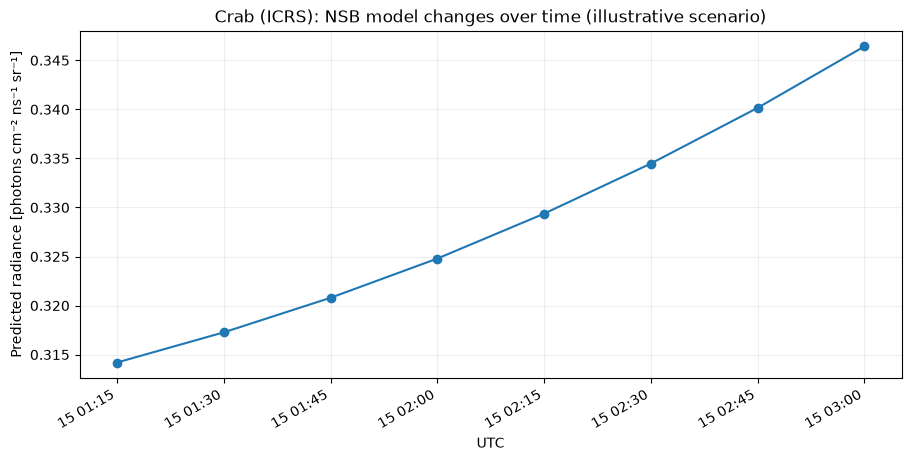

Predicted range for the selected scenario: 0.314194–0.346413 photons cm⁻² ns⁻¹ sr⁻¹


In [7]:
TIMES = [
    datetime(2024, 1, 15, 1, 15, tzinfo=timezone.utc) + timedelta(minutes=15 * i)
    for i in range(8)
]
TRACK = []
for instant in TIMES:
    predicted = evaluator.evaluate(
        nsb.PointQuery(observer, instant, equatorial)
    ).integrated_photons_cm2_ns_sr
    if not np.isfinite(predicted) or predicted < 0:
        raise ValueError(f"Invalid radiance at {instant.isoformat()}")
    TRACK.append(predicted)

fig, ax = plt.subplots(figsize=(9, 4.5), layout="constrained")
ax.plot(TIMES, TRACK, "o-")
ax.set(
    xlabel="UTC",
    ylabel=f"Predicted radiance [{UNIT}]",
    title="Crab (ICRS): NSB model changes over time (illustrative scenario)",
)
ax.grid(alpha=0.2)
fig.autofmt_xdate()
plt.show()

print(
    f"Predicted range for the selected scenario: "
    f"{min(TRACK):.6f}–{max(TRACK):.6f} {UNIT}"
)


## 5. Native observation planning with `ThresholdQuery`

`ThresholdQuery` accepts the same target types as `PointQuery`. The search below uses
an illustrative radiance ceiling over **01:15–03:00 UTC on 15 January 2024**, with
astronomical night (Sun altitude below −18°) and a target-altitude floor of 30°
(consistent with the Oxygen zenith-distance domain).

We run the planner once for the **Crab equatorial** target and once for a fixed
**horizontal** pointing. Returned intervals are adaptive-search results under the
documented empirical resolution assumptions; they are not certified continuous-time
enclosures. An empty result means no period satisfied the supplied settings.


In [8]:
start = datetime(2024, 1, 15, 1, 15, tzinfo=timezone.utc)
end = datetime(2024, 1, 15, 3, 0, tzinfo=timezone.utc)
threshold = 0.35  # Illustrative total radiance ceiling [photons cm⁻² ns⁻¹ sr⁻¹]

planning_targets = {
    "Equatorial (Crab)": equatorial,
    "Horizontal (alt=60°, az=130°)": horizontal,
}

rows = ["| Target frame | Start [UTC] | End [UTC] |", "|---|---|---|"]
for label, target in planning_targets.items():
    query = nsb.ThresholdQuery(
        observer,
        target,
        start,
        end,
        threshold,
        components=nsb.ComponentMask.ALL,
        sun_altitude_ceiling_deg=-18.0,
        target_altitude_floor_deg=30.0,
    )
    periods = evaluator.periods_below_threshold(query).periods
    if periods:
        for begin, finish in periods:
            rows.append(
                f"| {label} | {begin:%Y-%m-%d %H:%M:%S.%f} | "
                f"{finish:%Y-%m-%d %H:%M:%S.%f} |"
            )
    else:
        rows.append(f"| {label} | No intervals satisfy these settings | — |")

display(Markdown("\n".join(rows)))


| Target frame | Start [UTC] | End [UTC] |
|---|---|---|
| Equatorial (Crab) | 2024-01-15 01:15:00.000000 | 2024-01-15 03:00:00.000000 |
| Horizontal (alt=60°, az=130°) | 2024-01-15 01:15:00.000000 | 2024-01-15 02:03:30.900456 |
| Horizontal (alt=60°, az=130°) | 2024-01-15 02:05:36.078929 | 2024-01-15 03:00:00.000000 |

## 6. Physical interpretation and instrumental limitations

NSB predicts **ground-level optical photon radiance** integrated over a stated band.
A camera measures a detector signal that further depends on effective collecting area,
optics throughput, wavelength-dependent PDE/QE, pixel angular acceptance, electronic
noise treatment and calibration. Those instrument factors are **outside** the NSB
radiance API.

Dimensional conversion of band-integrated radiance into incident photons on an ideal
aperture is only a unit check. It must not be inverted into a spectrum, treated as
photoelectrons, or fitted as a camera gain. Automatic Airglow in the current release
line may select experimental Oxygen emission with a zenith-distance domain of ≤60°;
site profiles remain planning assumptions rather than measured calibrations.

Interpreting model output against an instrument therefore requires a separately
validated response model and observational comparison design. This notebook does not
perform that comparison. See [scientific validation](../docs/scientific-validation.md)
and [observational validation](observational-validation.ipynb) for the project's
evidence boundaries.


## 7. Conclusion

The public Python API demonstrated here supports:

- component-separated point evaluation at a declared observer, UTC instant and target;
- native **equatorial** (`siderust.direction.ICRS`) and **horizontal**
  (`siderust.direction.Horizontal`) targets in `PointQuery` and `ThresholdQuery`;
- adaptive observation-window searches under explicit radiance and geometric constraints.

Model domains and limitations remain those of the selected components and site profile:
planning presets are not observational calibrations; Automatic Airglow may include
experimental Oxygen within its stated domain; adaptive planning is empirical under
documented resolution assumptions and does not certify every unvisited instant.
Horizontal Starlight is time-dependent under Earth rotation, so certified constant-Starlight
enclosures do not apply to horizontal targets.

References: [CTAO public planning notebook](ctao-sky-background.ipynb),
[Python API](../docs/python.md),
[scientific validation](../docs/scientific-validation.md).
